# Nonlinear static analysis with structsolve

Two nonlinear static problems solved with `structsolve.Analysis` of
[structsolve](https://saullocastro.github.io/structsolve/):

1. a simply supported plate compressed along $x$ with a small transverse
   force at the centre, against the linearised solution and the
   amplification ceiling of the buckling load; the same model is checked in
   `tests/test_static_axial_load_nonlinear.py` (`test_static`);
2. a cantilever plate under a follower pressure, against the reference
   values of the plate_clpt_donnell model of panels and the hand-written
   Newton-Raphson iterations of the example *Follower pressure*; the same
   model is checked in `tests/test_follower_pressure_structsolve.py`.

## Theory

`structsolve.Analysis` solves the equilibrium
$\boldsymbol{R}(\boldsymbol{u}, \lambda) =
\boldsymbol{F}_{int}(\boldsymbol{u}) - \lambda \boldsymbol{F}_{ext} =
\boldsymbol{0}$ with the full Newton-Raphson method and the tangent
stiffness matrix

$$
\boldsymbol{K}_T = \boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL}(\boldsymbol{u})
+ \boldsymbol{K}_{GNL}(\boldsymbol{u}) + \boldsymbol{K}_G(\boldsymbol{u})
$$

given by four callables that loop over the elements and assemble:
`calc_fext` returns $\lambda \boldsymbol{F}_{ext}$, `calc_fint` the internal
forces of `update_fint`, `calc_kC` returns $\boldsymbol{K}_{C0}$, or
$\boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL} + \boldsymbol{K}_{GNL}$ with
`NLgeom=True`, and `calc_kG` returns $\boldsymbol{K}_G$, such that
`calc_kC + calc_kG` is $\boldsymbol{K}_T$. structsolve imposes no boundary
condition itself: the callables here work on the unknown degrees of freedom
`bu`, receiving `c = u[bu]` and returning vectors and matrices restricted to
`bu`. The convergence criterion is, by default, Crisfield's: the residual
and the reference forces, the external and the internal forces, are scaled
with the diagonal of the linear stiffness matrix over the free degrees of
freedom, and the iterations stop when their ratio is below
`Analysis.relTOL = 1e-9`. The scaled norm does not depend on the units of
the degrees of freedom, which mix displacements, slopes and $w_{,xy}$. A
tangent stiffness matrix that is the exact Jacobian of the internal forces
squares this residual at each iteration close to the solution.

In [1]:
%matplotlib inline
import numpy as np
from numpy import isclose
import matplotlib.pyplot as plt
from scipy.sparse import coo_matrix
from scipy.sparse.linalg import eigsh, spsolve

from composites import isotropic_plate
from structsolve import Analysis
from structsolve.convergence import crisfield_weights, crisfield_zeta

from bfscplate2d import (BFSCPlate2D, update_KC0, update_KCNL, update_KG,
        update_fint, update_fext_follower, update_KCfollower, DOF, DOUBLE,
        INT, KC0_SPARSE_SIZE, KCNL_SPARSE_SIZE, KG_SPARSE_SIZE,
        KCfollower_SPARSE_SIZE)
from bfscplate2d.quadrature import get_points_weights

## Compressed plate with a small transverse force

An isotropic plate, $a = 0.9$ m, $b = 0.5$ m, $h = 1$ mm, $E = 70$ GPa,
$\nu = 0.3$, meshed with 13 by 7 nodes and 4 integration points per
direction. The edges are simply supported: $w$ and its derivative along the
edge are zero, $w_{,y}$ on the edges $x$ = constant and $w_{,x}$ on the
edges $y$ = constant, such that $w$ vanishes along the whole edge and not
only at the nodes. $v = 0$ on the edges $x$ = constant and $u = 0$ along
$x = a/2$ remove the rigid-body motions. The test
`tests/test_static_axial_load_nonlinear.py` constrains $w$ only at the
nodes and keeps regression values of that model, so the numbers here differ
slightly from them and are not compared with them.

In [2]:
# number of nodes
nx = 13
ny = 7

# geometry
a = 0.9
b = 0.5

# material properties
E = 0.7e11
nu = 0.3
h = 0.001

points, weights = get_points_weights(nint=4)
lam = isotropic_plate(thickness=h, E=E, nu=nu)

xlin = np.linspace(0, a, nx)
ylin = np.linspace(0, b, ny)
xmesh, ymesh = np.meshgrid(xlin, ylin)
ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten())).T
x = ncoords[:, 0]
y = ncoords[:, 1]
nids = 1 + np.arange(ncoords.shape[0])
nid_pos = dict(zip(nids, np.arange(len(nids))))
nids_mesh = nids.reshape(nx, ny)
n1s = nids_mesh[:-1, :-1].flatten()
n2s = nids_mesh[1:, :-1].flatten()
n3s = nids_mesh[1:, 1:].flatten()
n4s = nids_mesh[:-1, 1:].flatten()
num_elements = len(n1s)
print('num_elements', num_elements)

N = DOF*nx*ny
KC0r = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=INT)
KC0c = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=INT)
KC0v = np.zeros(KC0_SPARSE_SIZE*num_elements, dtype=DOUBLE)
KCNLr = np.zeros(KCNL_SPARSE_SIZE*num_elements, dtype=INT)
KCNLc = np.zeros(KCNL_SPARSE_SIZE*num_elements, dtype=INT)
KCNLv = np.zeros(KCNL_SPARSE_SIZE*num_elements, dtype=DOUBLE)
KGr = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=INT)
KGc = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=INT)
KGv = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=DOUBLE)

elements = []
for k, (n1, n2, n3, n4) in enumerate(zip(n1s, n2s, n3s, n4s)):
    plate = BFSCPlate2D()
    plate.n1, plate.n2, plate.n3, plate.n4 = n1, n2, n3, n4
    plate.c1 = DOF*nid_pos[n1]
    plate.c2 = DOF*nid_pos[n2]
    plate.c3 = DOF*nid_pos[n3]
    plate.c4 = DOF*nid_pos[n4]
    plate.ABD = lam.ABD
    plate.lex = a/(nx - 1)
    plate.ley = b/(ny - 1)
    plate.init_k_KC0 = k*KC0_SPARSE_SIZE
    plate.init_k_KCNL = k*KCNL_SPARSE_SIZE
    plate.init_k_KG = k*KG_SPARSE_SIZE
    update_KC0(plate, points, weights, KC0r, KC0c, KC0v)
    elements.append(plate)
KC0 = coo_matrix((KC0v, (KC0r, KC0c)), shape=(N, N)).tocsc()

# simply supported edges, v = 0 at x = 0 and x = a, u = 0 along x = a/2
edges_x = isclose(x, 0) | isclose(x, a)
edges_y = isclose(y, 0) | isclose(y, b)
bk = np.zeros(N, dtype=bool)
bk[6::DOF] = edges_x | edges_y
bk[8::DOF] = edges_x
bk[7::DOF] = edges_y
bk[3::DOF] = edges_x
bk[0::DOF] = isclose(x, a/2)
bu = ~bk
print('unknown degrees of freedom', bu.sum())
KC0uu = KC0[bu, :][:, bu]

num_elements 72
unknown degrees of freedom 813


The assembly of the internal forces, of
$\boldsymbol{K}_{CNL} + \boldsymbol{K}_{GNL}$ and of $\boldsymbol{K}_G$ at
a displacement vector, and the callables of structsolve built on them. The
callable `calc_fint` also keeps the load factor and the internal forces of
each iteration, for the residual history:

In [3]:
def calc_fint(u):
    fint = np.zeros(N)
    for plate in elements:
        update_fint(u, plate, points, weights, fint)
    return fint


def calc_KCNL(u):
    """K_CNL + K_GNL at u"""
    KCNLv[:] = 0
    for plate in elements:
        update_KCNL(u, plate, points, weights, KCNLr, KCNLc, KCNLv)
    return coo_matrix((KCNLv, (KCNLr, KCNLc)), shape=(N, N)).tocsc()


def calc_KG(u):
    """K_G at u"""
    KGv[:] = 0
    for plate in elements:
        update_KG(u, plate, points, weights, KGr, KGc, KGv)
    return coo_matrix((KGv, (KGr, KGc)), shape=(N, N)).tocsc()


class Callables(object):
    """The callables of structsolve.Analysis under the external forces
    ``fext``, on the unknown degrees of freedom ``bu``"""
    def __init__(self, fext):
        self.fext = fext
        self.iterations = []

    def expand(self, c):
        u = np.zeros(N)
        u[bu] = c
        return u

    def calc_fext(self, inc=1., silent=False):
        return inc*self.fext[bu]

    def calc_fint(self, c, inc=1., silent=False):
        fint = calc_fint(self.expand(c))[bu]
        self.iterations.append((inc, fint))
        return fint

    def calc_kC(self, c=None, NLgeom=False, silent=False):
        if not NLgeom:
            return KC0uu
        return (KC0 + calc_KCNL(self.expand(c)))[bu, :][:, bu]

    def calc_kG(self, c=None, NLgeom=False, silent=False):
        return calc_KG(self.expand(c))[bu, :][:, bu]

The axial compression $P = 300$ N is applied as equal nodal forces $\pm
P/n_y$ on the edges $x = 0$ and $x = a$, and the transverse force
$F_t = 0.01$ N at the centre. The first buckling load $P_{cr}$ comes from
the linear buckling problem
$(\boldsymbol{K}_{C0} + \lambda \boldsymbol{K}_G)\boldsymbol{\phi} =
\boldsymbol{0}$, with $\boldsymbol{K}_G$ of the linear static solution of
$P$ alone:

In [4]:
load = 300.  # N
transverse = 0.01  # N

fext = np.zeros(N)
fext[0::DOF][isclose(x, 0)] = +load/ny
fext[0::DOF][isclose(x, a)] = -load/ny
ftrans = np.zeros(N)
ftrans[6::DOF][isclose(x, a/2) & isclose(y, b/2)] = transverse

u_axial = np.zeros(N)
u_axial[bu] = spsolve(KC0uu, fext[bu])
KG = calc_KG(u_axial)
KGuu = KG[bu, :][:, bu]
eigvals, eigvecsu = eigsh(A=KGuu, k=5, which='SM', M=KC0uu, tol=1e-6,
                          sigma=1., mode='cayley')
eigvals = -1./eigvals
load_cr = eigvals[0]*load
print('P_cr = %.4f N, P/P_cr = %.4f' % (load_cr, load/load_cr))

P_cr = 501.7188 N, P/P_cr = 0.5979


Below $P_{cr}$ and for a deflection small compared with the thickness, the
membrane stretching of the von Kármán terms is negligible and the answer is
the linearised one, the transverse force resisted by the bending stiffness
reduced by the geometric stiffness of the axial load,

$$
\boldsymbol{u}_{lin} = \left( \boldsymbol{K}_{C0} + \boldsymbol{K}_G(P)
\right)^{-1} \boldsymbol{F}_t
$$

Its amplification over the response to the transverse force alone,
$\boldsymbol{K}_{C0}^{-1} \boldsymbol{F}_t$, is below the single-mode
ceiling $1/(1 - P/P_{cr})$, since a point load excites many modes:

In [5]:
u_lin = np.zeros(N)
u_lin[bu] = spsolve((KC0 + KG)[bu, :][:, bu], ftrans[bu])
w_lin = u_lin[6::DOF].max()

u_bend = np.zeros(N)
u_bend[bu] = spsolve(KC0uu, ftrans[bu])
w_bend = u_bend[6::DOF].max()
print('w_max of the transverse force alone: %.6e m' % w_bend)
print('w_max linearised:                    %.6e m' % w_lin)

w_max of the transverse force alone: 6.303565e-06 m
w_max linearised:                    1.110397e-05 m


structsolve solves the nonlinear equilibrium under the combined loads in
one increment. Crisfield's relative residual of each iteration is
recomputed from the internal forces kept by `calc_fint`:

In [6]:
callables = Callables(fext + ftrans)
an = Analysis(calc_fext=callables.calc_fext,
              calc_fint=callables.calc_fint,
              calc_kC=callables.calc_kC,
              calc_kG=callables.calc_kG)
an.initialInc = 1.
an.maxInc = 1.
increments_done, cs = an.static(NLgeom=True)
print('converged load factors', increments_done)
u = callables.expand(cs[-1])

weights_crisfield = crisfield_weights(KC0uu)
f = (fext + ftrans)[bu]
history = [crisfield_zeta(inc*f - fint, inc*f, fint, weights_crisfield)
           for inc, fint in callables.iterations if inc == 1.]
for i, zeta in enumerate(history):
    print('iteration %d, Crisfield residual %.3e' % (i, zeta))

Started Non-Linear Static Analysis
	___________________________________________
	                                           
	Newton-Raphson solver
	___________________________________________
	Initializing...
	Step 1, attempting load factor 1.00000
		Iteration: 1, max(|R|) = 3.145e-03, zeta = 4.009e-04
		Iteration: 2, max(|R|) = 2.297e-03, zeta = 4.095e-05
		Iteration: 3, max(|R|) = 1.739e-11, zeta = 2.785e-12
		Converged at load factor 1.00000
Finished Non-Linear Static Analysis
	    load factor 1.00000
converged load factors [1.0]
iteration 0, Crisfield residual 4.009e-04
iteration 1, Crisfield residual 4.095e-05
iteration 2, Crisfield residual 2.785e-12


In [7]:
w = u[6::DOF].reshape(nx, ny).T
w_max = w.max()
amplification = w_max/w_bend
ceiling = 1./(1. - load/load_cr)
print('w_max/h = %.4f' % (w_max/h))
print()
print('%-22s %14s %14s %12s' % ('', 'structsolve', 'reference', 'rel. diff'))
print('%-22s %14.6e %14.6e %12.2e' % ('w_max (m), linearised', w_max, w_lin,
                                      w_max/w_lin - 1))
print('%-22s %14.4f %14.4f %12.2e' % ('amplification, ceiling',
                                      amplification, ceiling,
                                      amplification/ceiling - 1))

w_max/h = 0.0111

                          structsolve      reference    rel. diff
w_max (m), linearised    1.110364e-05   1.110397e-05    -2.95e-05
amplification, ceiling         1.7615         2.4872    -2.92e-01


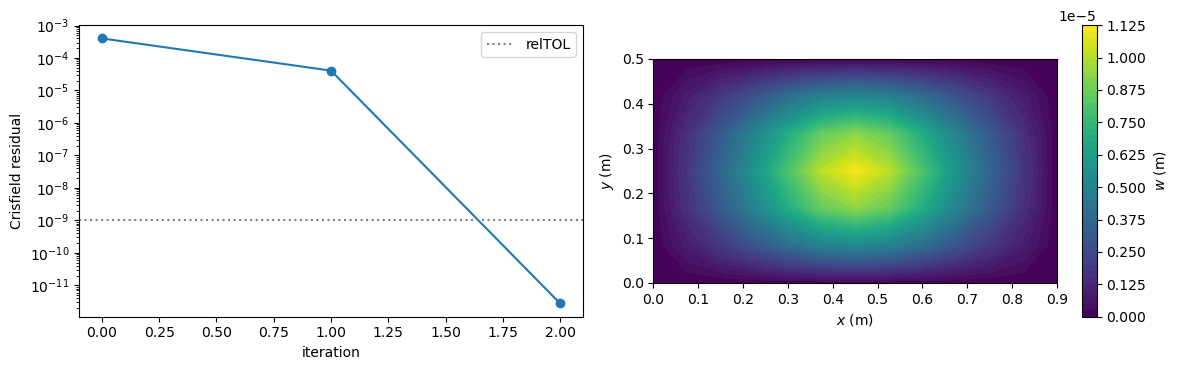

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
axes[0].semilogy(history, 'o-')
axes[0].axhline(an.relTOL, color='gray', ls=':', label='relTOL')
axes[0].set_xlabel('iteration')
axes[0].set_ylabel('Crisfield residual')
axes[0].legend()
axes[1].set_aspect('equal')
cf = axes[1].contourf(xmesh, ymesh, w, levels=50)
fig.colorbar(cf, ax=axes[1], label='$w$ (m)')
axes[1].set_xlabel('$x$ (m)')
axes[1].set_ylabel('$y$ (m)')
plt.tight_layout()
plt.show()

$P = 300$ N is 0.598 of $P_{cr} = 501.72$ N, and the deflection stays
small, $w_{max}/h = 0.0111$: the solution of structsolve equals the
linearised one within $3.0 \times 10^{-5}$. The amplification over the
response to the transverse force alone, 1.76, is between 1 and the
single-mode ceiling 2.49. structsolve converges in three iterations; the last
one takes Crisfield's residual from $4.1 \times 10^{-5}$ to
$2.8 \times 10^{-12}$, below its square, the quadratic convergence of a
tangent stiffness matrix that is the Jacobian of the internal forces. The
first iterations are not a fair measure of the convergence rate, since the
residual is normalised by the whole external load, whose axial part may be
in equilibrium after the first iteration while the out-of-plane part is not.

## Follower pressure

A follower pressure stays normal to the deformed mid-surface and acts on its
deformed area [1, 2]. Its force vector $\boldsymbol{F}_p(\boldsymbol{u})$
depends on the displacements, and its derivative, the load stiffness matrix
$\boldsymbol{K}_F = -\partial \boldsymbol{F}_p/\partial \boldsymbol{u}$,
enters the tangent stiffness matrix. structsolve passes the load factor
`inc` to the callables that declare it. With the load factor $\lambda$,
`calc_fext` gives the dead part $\lambda \boldsymbol{F}_p(\boldsymbol{0})$,
`calc_fint` adds $-\lambda (\boldsymbol{F}_p(\boldsymbol{u}) -
\boldsymbol{F}_p(\boldsymbol{0}))$, the part of `update_fext_follower` with
`reference=0`, to the internal forces, and `calc_kC` adds the load stiffness
matrix of $\lambda p$, such that the residual of structsolve is

$$
\boldsymbol{R} = \boldsymbol{F}_{int}(\boldsymbol{u}) - \lambda
\boldsymbol{F}_p(\boldsymbol{u})
$$

and its Jacobian $\boldsymbol{K}_{C0} + \boldsymbol{K}_{CNL} +
\boldsymbol{K}_{GNL} + \boldsymbol{K}_G + \boldsymbol{K}_F$, unsymmetric for
the free edges of the cantilever and solved with LU factorisations.

A helper class builds the mesh of $n_x$ by $n_y$ nodes, with 6 integration
points per direction, gives the pressure `p` of each element at its
integration points and assembles $\boldsymbol{K}_{C0}$; `boundary_flags`
constrains, along an edge, a displacement and its derivative along the
edge:

In [9]:
NINT = 6
TRUNCATIONS = [0, 1]


class Mesh(object):
    """Rectangular mesh of ``nx`` by ``ny`` nodes over ``a`` by ``b``, with
    the assembly of the vectors and matrices used below"""
    def __init__(self, nx, ny, a, b, lam, nint=NINT):
        self.a, self.b = a, b
        self.points, self.weights = get_points_weights(nint=nint)
        xlin = np.linspace(0, a, nx)
        ylin = np.linspace(0, b, ny)
        xmesh, ymesh = np.meshgrid(xlin, ylin)
        ncoords = np.vstack((xmesh.T.flatten(), ymesh.T.flatten())).T
        self.x = ncoords[:, 0]
        self.y = ncoords[:, 1]
        nids_mesh = np.arange(nx*ny).reshape(nx, ny)
        n1s = nids_mesh[:-1, :-1].flatten()
        n2s = nids_mesh[1:, :-1].flatten()
        n3s = nids_mesh[1:, 1:].flatten()
        n4s = nids_mesh[:-1, 1:].flatten()
        self.N = DOF*nx*ny
        self.elements = []
        for k, (n1, n2, n3, n4) in enumerate(zip(n1s, n2s, n3s, n4s)):
            plate = BFSCPlate2D()
            plate.n1, plate.n2, plate.n3, plate.n4 = n1, n2, n3, n4
            plate.c1 = DOF*n1
            plate.c2 = DOF*n2
            plate.c3 = DOF*n3
            plate.c4 = DOF*n4
            plate.ABD = lam.ABD
            plate.lex = a/(nx - 1)
            plate.ley = b/(ny - 1)
            plate.init_k_KC0 = k*KC0_SPARSE_SIZE
            plate.init_k_KCNL = k*KCNL_SPARSE_SIZE
            plate.init_k_KG = k*KG_SPARSE_SIZE
            plate.init_k_KCfollower = k*KCfollower_SPARSE_SIZE
            self.elements.append(plate)
        self.h = lam.h

    def pressure(self, plate, func):
        """``p[i, j]`` at ``xi = points[i]``, ``eta = points[j]``"""
        x1, y1 = self.x[plate.n1], self.y[plate.n1]
        x = x1 + plate.lex*(self.points + 1)/2
        y = y1 + plate.ley*(self.points + 1)/2
        p = func(x[:, None], y[None, :])*np.ones((x.size, y.size))
        return np.ascontiguousarray(p, dtype=DOUBLE)

    def KC0(self):
        n = KC0_SPARSE_SIZE*len(self.elements)
        r = np.zeros(n, dtype=INT)
        c = np.zeros(n, dtype=INT)
        v = np.zeros(n, dtype=DOUBLE)
        for plate in self.elements:
            update_KC0(plate, self.points, self.weights, r, c, v)
        return coo_matrix((v, (r, c)), shape=(self.N, self.N)).tocsc()


def boundary_flags(m, edges):
    """Constrained degrees of freedom: for each edge in ``edges``, a dict
    ``{'x1': 'w', ...}`` of the displacements set to zero along it, with
    their derivatives along the edge"""
    bk = np.zeros(m.N, dtype=bool)
    on = {'x1': isclose(m.x, 0), 'x2': isclose(m.x, m.a),
          'y1': isclose(m.y, 0), 'y2': isclose(m.y, m.b)}
    along = {'x': {'u': (0, 2), 'v': (3, 5), 'w': (6, 8)},
             'y': {'u': (0, 1), 'v': (3, 4), 'w': (6, 7)}}
    for edge, fields in edges.items():
        for f in fields:
            for i in along[edge[0]][f]:
                bk[i::DOF] |= on[edge]
    return bk

The callables of the follower pressure `func(x, y)` times the load factor,
for the truncation `quadratic` of the area vector:

In [10]:
class FollowerCallables(object):
    """The callables of structsolve.Analysis for the mesh ``m`` under the
    follower pressure ``func(x, y)`` times the load factor, on the unknown
    degrees of freedom ``bu``"""
    def __init__(self, m, bu, func, quadratic):
        self.m = m
        self.bu = bu
        self.quadratic = quadratic
        self.pressures = [m.pressure(plate, func) for plate in m.elements]
        self.KC0 = m.KC0()
        num_elements = len(m.elements)
        self.KCNLr = np.zeros(KCNL_SPARSE_SIZE*num_elements, dtype=INT)
        self.KCNLc = np.zeros(KCNL_SPARSE_SIZE*num_elements, dtype=INT)
        self.KCNLv = np.zeros(KCNL_SPARSE_SIZE*num_elements, dtype=DOUBLE)
        self.KGr = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=INT)
        self.KGc = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=INT)
        self.KGv = np.zeros(KG_SPARSE_SIZE*num_elements, dtype=DOUBLE)
        self.KCfr = np.zeros(KCfollower_SPARSE_SIZE*num_elements, dtype=INT)
        self.KCfc = np.zeros(KCfollower_SPARSE_SIZE*num_elements, dtype=INT)
        self.KCfv = np.zeros(KCfollower_SPARSE_SIZE*num_elements,
                             dtype=DOUBLE)
        # the dead part of the pressure, the force vector at u = 0
        self.fp0 = np.zeros(m.N, dtype=DOUBLE)
        for plate, p in zip(m.elements, self.pressures):
            update_fext_follower(np.zeros(m.N), plate, m.points, m.weights,
                                 p, self.fp0, quadratic)

    def expand(self, c):
        u = np.zeros(self.m.N, dtype=DOUBLE)
        u[self.bu] = c
        return u

    def calc_fext(self, inc=1., silent=False):
        return inc*self.fp0[self.bu]

    def calc_fint(self, c, inc=1., silent=False):
        m = self.m
        u = self.expand(c)
        fint = np.zeros(m.N, dtype=DOUBLE)
        for plate, p in zip(m.elements, self.pressures):
            update_fint(u, plate, m.points, m.weights, fint)
            # minus the part of the follower pressure that depends on u
            update_fext_follower(u, plate, m.points, m.weights, -inc*p, fint,
                                 self.quadratic, 0)
        return fint[self.bu]

    def calc_kC(self, c=None, NLgeom=False, inc=1., silent=False):
        bu = self.bu
        if not NLgeom:
            return self.KC0[bu, :][:, bu]
        m = self.m
        u = self.expand(c)
        self.KCNLv *= 0
        self.KCfv *= 0
        for plate, p in zip(m.elements, self.pressures):
            update_KCNL(u, plate, m.points, m.weights, self.KCNLr,
                        self.KCNLc, self.KCNLv)
            # the load stiffness matrix of the pressure inc*p
            update_KCfollower(u, plate, m.points, m.weights, inc*p,
                              self.KCfr, self.KCfc, self.KCfv,
                              self.quadratic)
        KCNL = coo_matrix((self.KCNLv, (self.KCNLr, self.KCNLc)),
                          shape=(m.N, m.N))
        KCf = coo_matrix((self.KCfv, (self.KCfr, self.KCfc)),
                         shape=(m.N, m.N))
        return (self.KC0 + KCNL + KCf).tocsc()[bu, :][:, bu]

    def calc_kG(self, c=None, NLgeom=False, silent=False):
        m = self.m
        u = self.expand(c)
        self.KGv *= 0
        for plate in m.elements:
            update_KG(u, plate, m.points, m.weights, self.KGr, self.KGc,
                      self.KGv)
        KG = coo_matrix((self.KGv, (self.KGr, self.KGc)), shape=(m.N, m.N))
        return KG.tocsc()[self.bu, :][:, self.bu]

The square isotropic cantilever of the example *Follower pressure*,
$a = b = 0.3$ m, $h = 2$ mm, $E = 70$ GPa, $\nu = 0.3$, 10 by 10 elements,
clamped at $x = 0$, the other edges free, under a uniform follower pressure
$p = 2$ kPa pushing along $+z$, in five equal load increments:

In [11]:
E_c, nu_c, h_c = 70.e9, 0.3, 2.e-3
a_c = b_c = 0.3
nel = 10
mc = Mesh(nx=nel + 1, ny=nel + 1, a=a_c, b=b_c,
          lam=isotropic_plate(thickness=h_c, E=E_c, nu=nu_c))
bkc = boundary_flags(mc, {'x1': 'uvw'})
bkc[7::DOF] |= isclose(mc.x, 0)
bkc[9::DOF] |= isclose(mc.x, 0)
buc = ~bkc
func = lambda x, y: 2.e3 + 0*x*y
tip = np.where(isclose(mc.x, a_c) & isclose(mc.y, b_c/2))[0][0]

results = {}
for quadratic in TRUNCATIONS:
    fc = FollowerCallables(mc, buc, func, quadratic)
    an = Analysis(calc_fext=fc.calc_fext, calc_fint=fc.calc_fint,
                  calc_kC=fc.calc_kC, calc_kG=fc.calc_kG)
    an.initialInc = 0.2
    an.maxInc = 0.2
    increments_done, cs = an.static(NLgeom=True)
    print('quadratic=%d, converged load factors %s' % (quadratic,
          np.round(increments_done, 6)))
    path = [fc.expand(ci)[DOF*tip + 6]/h_c for ci in cs]
    uc = fc.expand(cs[-1])
    results[quadratic] = dict(w=uc[DOF*tip + 6]/h_c, u=uc[DOF*tip],
                              lbd=np.concatenate(([0.], increments_done)),
                              path=np.concatenate(([0.], path)))

Started Non-Linear Static Analysis
	___________________________________________
	                                           
	Newton-Raphson solver
	___________________________________________
	Initializing...
	Step 1, attempting load factor 0.20000
		Iteration: 1, max(|R|) = 3.067e+03, zeta = 1.000e+00
		Iteration: 2, max(|R|) = 6.677e-02, zeta = 7.519e-02
		Iteration: 3, max(|R|) = 5.288e-02, zeta = 8.765e-03
		Iteration: 4, max(|R|) = 6.037e-07, zeta = 9.849e-08


		Iteration: 5, max(|R|) = 8.899e-12, zeta = 2.621e-12
		Converged at load factor 0.20000
	Step 2, attempting load factor 0.40000
		Iteration: 1, max(|R|) = 6.089e+03, zeta = 1.000e+00
		Iteration: 2, max(|R|) = 3.834e-01, zeta = 2.133e-01
		Iteration: 3, max(|R|) = 7.699e-01, zeta = 5.523e-02
		Iteration: 4, max(|R|) = 4.006e-04, zeta = 3.193e-05
		Iteration: 5, max(|R|) = 1.798e-08, zeta = 1.359e-09


		Iteration: 6, max(|R|) = 5.338e-11, zeta = 5.848e-12
		Converged at load factor 0.40000
	Step 3, attempting load factor 0.60000
		Iteration: 1, max(|R|) = 5.957e+03, zeta = 1.000e+00
		Iteration: 2, max(|R|) = 3.547e-01, zeta = 1.291e-01
		Iteration: 3, max(|R|) = 3.354e-01, zeta = 1.320e-02
		Iteration: 4, max(|R|) = 9.290e-05, zeta = 5.498e-06
		Iteration: 5, max(|R|) = 1.259e-10, zeta = 9.890e-12
		Converged at load factor 0.60000
	Step 4, attempting load factor 0.80000
		Iteration: 1, max(|R|) = 5.926e+03, zeta = 1.000e+00


		Iteration: 2, max(|R|) = 2.161e-01, zeta = 5.788e-02
		Iteration: 3, max(|R|) = 7.592e-02, zeta = 5.124e-03
		Iteration: 4, max(|R|) = 1.771e-06, zeta = 1.092e-07
		Iteration: 5, max(|R|) = 2.380e-10, zeta = 1.173e-11
		Converged at load factor 0.80000
	Step 5, attempting load factor 1.00000
		Iteration: 1, max(|R|) = 5.981e+03, zeta = 1.000e+00
		Iteration: 2, max(|R|) = 1.306e-01, zeta = 3.192e-02


		Iteration: 3, max(|R|) = 2.058e-01, zeta = 1.114e-02
		Iteration: 4, max(|R|) = 1.895e-08, zeta = 5.569e-09
		Iteration: 5, max(|R|) = 5.378e-10, zeta = 1.587e-11
		Converged at load factor 1.00000
Finished Non-Linear Static Analysis
	    load factor 1.00000
quadratic=0, converged load factors [0.2 0.4 0.6 0.8 1. ]
Started Non-Linear Static Analysis
	___________________________________________
	                                           
	Newton-Raphson solver
	___________________________________________
	Initializing...
	Step 1, attempting load factor 0.20000
		Iteration: 1, max(|R|) = 3.067e+03, zeta = 1.000e+00
		Iteration: 2, max(|R|) = 6.677e-02, zeta = 7.519e-02


		Iteration: 3, max(|R|) = 5.288e-02, zeta = 8.765e-03
		Iteration: 4, max(|R|) = 6.037e-07, zeta = 9.849e-08
		Iteration: 5, max(|R|) = 9.199e-12, zeta = 2.869e-12
		Converged at load factor 0.20000
	Step 2, attempting load factor 0.40000
		Iteration: 1, max(|R|) = 6.089e+03, zeta = 1.000e+00
		Iteration: 2, max(|R|) = 3.834e-01, zeta = 2.133e-01


		Iteration: 3, max(|R|) = 7.699e-01, zeta = 5.523e-02
		Iteration: 4, max(|R|) = 4.006e-04, zeta = 3.193e-05
		Iteration: 5, max(|R|) = 1.797e-08, zeta = 1.361e-09
		Iteration: 6, max(|R|) = 8.478e-11, zeta = 6.873e-12
		Converged at load factor 0.40000
	Step 3, attempting load factor 0.60000
		Iteration: 1, max(|R|) = 5.957e+03, zeta = 1.000e+00


		Iteration: 2, max(|R|) = 3.547e-01, zeta = 1.291e-01
		Iteration: 3, max(|R|) = 3.354e-01, zeta = 1.320e-02
		Iteration: 4, max(|R|) = 9.290e-05, zeta = 5.498e-06
		Iteration: 5, max(|R|) = 2.001e-10, zeta = 1.051e-11
		Converged at load factor 0.60000
	Step 4, attempting load factor 0.80000
		Iteration: 1, max(|R|) = 5.926e+03, zeta = 1.000e+00


		Iteration: 2, max(|R|) = 2.161e-01, zeta = 5.788e-02
		Iteration: 3, max(|R|) = 7.592e-02, zeta = 5.124e-03
		Iteration: 4, max(|R|) = 1.771e-06, zeta = 1.092e-07
		Iteration: 5, max(|R|) = 2.190e-10, zeta = 1.282e-11
		Converged at load factor 0.80000
	Step 5, attempting load factor 1.00000
		Iteration: 1, max(|R|) = 5.981e+03, zeta = 1.000e+00


		Iteration: 2, max(|R|) = 1.306e-01, zeta = 3.192e-02
		Iteration: 3, max(|R|) = 2.058e-01, zeta = 1.114e-02
		Iteration: 4, max(|R|) = 1.892e-08, zeta = 5.563e-09
		Iteration: 5, max(|R|) = 4.076e-10, zeta = 1.670e-11
		Converged at load factor 1.00000
Finished Non-Linear Static Analysis
	    load factor 1.00000
quadratic=1, converged load factors [0.2 0.4 0.6 0.8 1. ]


No closed-form solution applies to the large deflection of a flat plate
under a follower pressure, so the reference values are those of the
plate_clpt_donnell model of panels, the same von Kármán strains and area
vector discretized with $m = n = 16$ Bardell functions [3] and
$20 \times 20$ Gauss points, solved with the Newton-Raphson method of
structsolve with 10 increments and `relTOL = 1e-11`. Refining from
$m = n = 12$ changes $w$ by $2 \times 10^{-4}$; the mesh of 10 by 10
elements used here is within $5 \times 10^{-4}$ of these values (20 by 20
elements: $5 \times 10^{-5}$), both converging from below. The values,
$w/h$ and $u$ at the middle of the free edge $(a, b/2)$, are those stored in
the tests as `PANELS`.

The tip displacements are also compared with those of the hand-written
Newton-Raphson iterations of the example *Follower pressure*, the same model
with the same load increments, as printed there (`NR`).

In [12]:
# reference values of the plate_clpt_donnell model of panels, w/h and u (m)
# at (a, b/2) of the cantilever
PANELS = {
    'dead': dict(w=20.05040761, u=-3.06710517e-03),
    0: dict(w=20.23571166, u=-3.12566486e-03),
    1: dict(w=20.23571209, u=-3.12566500e-03),
}

# printed by the example Follower pressure
NR = {0: dict(w=20.22608292, u=-3.12295020e-03), 1: dict(w=20.22608335, u=-3.12295035e-03)}
REFERENCES = [('panels', PANELS), ('NR', NR)]

print('%-22s %12s %12s %10s  %14s %14s %10s' % ('reference', 'w/h', 'ref.',
      'rel. diff', 'u (m)', 'ref.', 'rel. diff'))
for quadratic in TRUNCATIONS:
    w, u_ = results[quadratic]['w'], results[quadratic]['u']
    for name, ref in REFERENCES:
        wr, ur = ref[quadratic]['w'], ref[quadratic]['u']
        print('%-22s %12.8f %12.8f %10.2e  %14.8e %14.8e %10.2e' % (
              'quadratic=%d, %s' % (quadratic, name), w, wr, w/wr - 1,
              u_, ur, u_/ur - 1))

reference                       w/h         ref.  rel. diff           u (m)           ref.  rel. diff
quadratic=0, panels     20.22608292  20.23571166  -4.76e-04  -3.12295020e-03 -3.12566486e-03  -8.69e-04
quadratic=0, NR         20.22608292  20.22608292  -1.23e-10  -3.12295020e-03 -3.12295020e-03   8.25e-10
quadratic=1, panels     20.22608335  20.23571209  -4.76e-04  -3.12295035e-03 -3.12566500e-03  -8.69e-04
quadratic=1, NR         20.22608335  20.22608335   1.12e-10  -3.12295035e-03 -3.12295035e-03  -1.18e-09


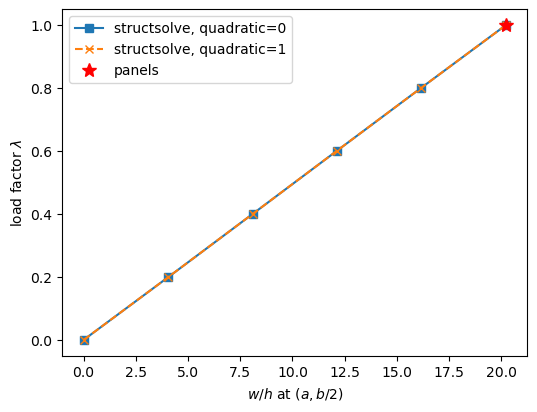

In [13]:
plt.figure(figsize=(6, 4.5))
for quadratic, style in zip(TRUNCATIONS, ['C0-s', 'C1--x']):
    plt.plot(results[quadratic]['path'], results[quadratic]['lbd'], style,
             label='structsolve, quadratic=%d' % quadratic)
plt.plot(PANELS[0]['w'], 1., 'r*', ms=10, label='panels')
plt.xlabel('$w/h$ at $(a, b/2)$')
plt.ylabel(r'load factor $\lambda$')
plt.legend()
plt.show()

Every increment converges, in 5 or 6 iterations, for both truncations. The
tip deflection, $w/h = 20.2261$, and the tip displacement,
$u = -3.1230 \times 10^{-3}$ m, are $4.8 \times 10^{-4}$ and
$8.7 \times 10^{-4}$ below the reference values of panels, and equal, to
the printed digits, to those of the hand-written Newton-Raphson iterations
of the example *Follower pressure*: the same equilibrium, solved by
structsolve with the follower pressure split into the dead part and the
part that depends on the displacements.

## References

1. Hibbitt, H. D., Some follower forces and load stiffness, *International Journal for Numerical Methods in Engineering*, 14(6), 937-941, 1979, doi:10.1002/nme.1620140613.
2. Schweizerhof, K., and Ramm, E., Displacement dependent pressure loads in nonlinear finite element analyses, *Computers & Structures*, 18(6), 1099-1114, 1984, doi:10.1016/0045-7949(84)90154-8.
3. Castro, S. G. P., and Donadon, M. V., Assembly of semi-analytical models to address linear buckling and vibration of stiffened composite panels with debonding defect, *Composite Structures*, 160, 232-247, 2017, doi:10.1016/j.compstruct.2016.10.026.